# Unsupervised Learning: Clustering and Dimensionality Reduction

Exploring k-means, GMMs, PCA, and t-SNE for unsupervised learning tasks.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aryabhardwaj23/AI-PROJECTS/blob/main/Machine%20learning/Latent%20Variable%20Models%20and%20Neural%20Networks%2091/Unsupervised%20Learning.ipynb)

# **Unsupervised Learning**

In [ ]:
import pandas as pd
import numpy as np
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

**I Load Task2C labeled.csv, Task2C unlabeled.csv, and Task2C test.csv datasets, along with the required libraries. Note that we will use both Task2C labeled.csv and Task2C unlabeled.csv to train the autoencoder, and only Task2C labeled.csv to train the classifiers. Finally, we will evaluate the trained classifier on the test dataset Task2C test.csv.**

In [ ]:
# Load datasets
labeled = pd.read_csv('Task2C_labeled.csv')
unlabeled = pd.read_csv('Task2C_unlabeled.csv')
test = pd.read_csv('Task2C_test.csv')

# Separate features and labels
X_labeled = labeled.drop('label', axis=1).values
y_labeled = labeled['label'].values
X_unlabeled = unlabeled.values
X_test = test.drop('label', axis=1).values
y_test = test['label'].values

# Combine labeled and unlabeled data for autoencoder training
X_autoenc = np.vstack([X_labeled, X_unlabeled])


**II Train an autoencoder with only one hidden layer and change the number of its neurons to 20, 60, 100, ..., 220 (i.e. from 20 to 220 with a step size of 40).**

In [ ]:
hidden_sizes = list(range(20, 221, 40))
autoencoders = {}
encoders = {}

for h in hidden_sizes:
    inp = Input(shape=(X_autoenc.shape[1],))
    encoded = Dense(h, activation='relu')(inp)
    decoded = Dense(X_autoenc.shape[1], activation='linear')(encoded)
    autoencoder = Model(inp, decoded)
    encoder = Model(inp, encoded)
    autoencoder.compile(optimizer=Adam(0.001), loss='mse')
    autoencoder.fit(X_autoenc, X_autoenc, epochs=30, batch_size=64, verbose=0)
    autoencoders[h] = autoencoder
    encoders[h] = encoder

**III For each model in Step II, calculate and record the reconstruction error for the autoencoder, which is simply the average of Euclidean distances between the input and output of the autoencoder. Plot these values where the x-axis is the number of units in the middle layer and the y-axis is the reconstruction error. Then, explain our findings based on the plot.**

49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


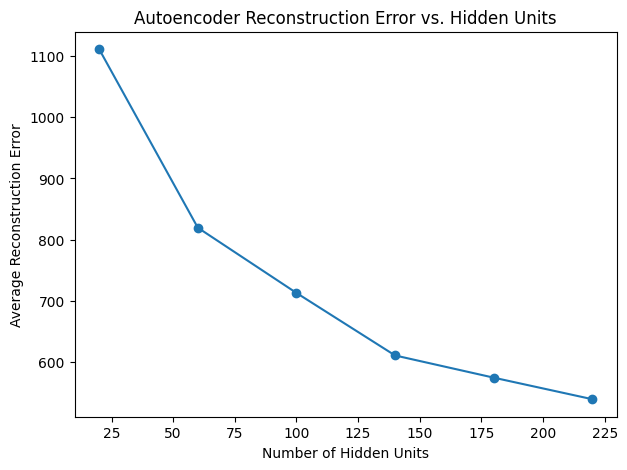

In [ ]:
recon_errors = []
for h in hidden_sizes:
    X_recon = autoencoders[h].predict(X_autoenc)
    error = np.mean(np.linalg.norm(X_autoenc - X_recon, axis=1))  # Euclidean distance
    recon_errors.append(error)

plt.figure(figsize=(7,5))
plt.plot(hidden_sizes, recon_errors, marker='o')
plt.xlabel('Number of Hidden Units')
plt.ylabel('Average Reconstruction Error')
plt.title('Autoencoder Reconstruction Error vs. Hidden Units')
plt.show()

The plot shows how the average reconstruction error of the autoencoder changes as you increase the number of hidden units in the middle layer. The x-axis represents the number of hidden units, and the y-axis shows the reconstruction error, which is the average Euclidean distance between each input and its reconstruction.

Findings based on the plot:

- As the number of hidden units increases, the reconstruction error decreases steadily.
- With a small number of hidden units, the autoencoder cannot capture enough information about the input, leading to high reconstruction error.
- Increasing the hidden layer size allows the autoencoder to learn more complex representations and reconstruct the input data more accurately, so the error drops.
- The decrease in error becomes less steep as the number of hidden units grows, indicating diminishing returns: after a certain point, adding more hidden units provides only a small improvement in reconstruction ability.


**IV Build the 3-layer NN to build a classification model using all the original attributes from the training set and change the number of its neurons to 20, 60, 100, ..., 220 (i.e. from 20 to 220 with a step size of 40). For each model, calculate and record the test error.**

In [ ]:
nn_errors = []
for h in hidden_sizes:
    clf = MLPClassifier(hidden_layer_sizes=(h,), max_iter=1000, random_state=42)
    clf.fit(X_labeled, y_labeled)
    y_pred = clf.predict(X_test)
    error = 1 - accuracy_score(y_test, y_pred)
    nn_errors.append(error)

**V Build augmented self-taught networks using the models learnt in Step II. For each model:**

**1) Add the output of the middle layer of an autoencoder as extra features to the original feature set;**

**2) Train a new 3-layer Neural Network using all features (original + extra) and varying the number of hidden neurons (like Step IV) as well.**

**3) Then calculate and record the test error.**
**For example, each model should be developed as follows: Model 1: 20 hidden neurons + extra 20 features (from an autoencoder), Model 2: 60 hidden neurons + extra 60 features (from an autoencoder), ..., Model 5: 220 hidden neurons + extra 220 features (from an autoencoder).**

In [ ]:
aug_errors = []
for h in hidden_sizes:
    # Extract features from encoder for labeled and test sets
    X_labeled_enc = encoders[h].predict(X_labeled)
    X_test_enc = encoders[h].predict(X_test)
    # Concatenate original and encoded features
    X_labeled_aug = np.hstack([X_labeled, X_labeled_enc])
    X_test_aug = np.hstack([X_test, X_test_enc])
    # Train and evaluate
    clf = MLPClassifier(hidden_layer_sizes=(h,), max_iter=1000, random_state=42)
    clf.fit(X_labeled_aug, y_labeled)
    y_pred = clf.predict(X_test_aug)
    error = 1 - accuracy_score(y_test, y_pred)
    aug_errors.append(error)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


**VI Plot the error rates for the 3-layer neural networks from Step IV and the augmented self- taught networks from Step V, while the x-axis is the number of hidden neurons and y-axis is the classification error. Explain the performance of the 3-layer neural networks and the augmented self-taught networks is different.**

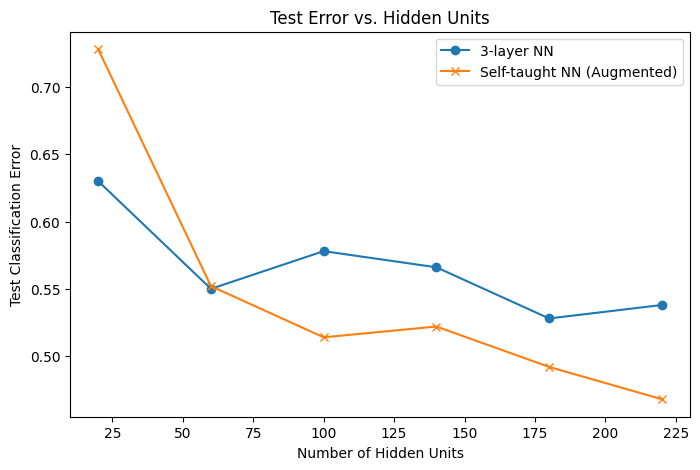

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(hidden_sizes, nn_errors, marker='o', label='3-layer NN')
plt.plot(hidden_sizes, aug_errors, marker='x', label='Self-taught NN (Augmented)')
plt.xlabel('Number of Hidden Units')
plt.ylabel('Test Classification Error')
plt.title('Test Error vs. Hidden Units')
plt.legend()
plt.show()


The plot compares the test classification error of standard 3-layer neural networks (blue line) and augmented self-taught networks (orange line) as the number of hidden units increases.

Explanation of Performance Differences:

- Self-taught networks consistently achieve lower test error than standard 3-layer NNs for all hidden unit sizes except the smallest (20), where the error is initially higher but quickly drops below the standard NN as the hidden size increases.
- As the number of hidden units grows, the error for the self-taught network continues to decrease, while the error for the standard NN plateaus or decreases more slowly.
- This indicates that adding features learned by the autoencoder (trained on both labeled and unlabeled data) provides extra information that helps the neural network generalize better on the test set, especially as model capacity increases.

- The standard 3-layer NN only uses the original features from labeled data, so its ability to capture complex patterns is limited by the labeled dataset size and feature richness.
- The self-taught network augments the original features with representations learned from both labeled and unlabeled data via the autoencoder. These learned features capture additional structure and patterns present in the data, improving the classifier's performance—particularly when the number of hidden units is large enough to utilize the extra information.
- As a result, the self-taught approach leverages unsupervised learning to enhance supervised learning, leading to lower test errors and better scalability as model complexity increases.

The self-taught (augmented) networks outperform standard 3-layer NNs because they benefit from richer, more informative features learned from both labeled and unlabeled data, leading to improved classification accuracy as the network size grows.

